# Figure: Benchmark Prediction Comparison

Two-panel figure comparing proT with the benchmark models on the **test split**:

- (a) synthetic dataset (`ishigami`)
- (b) real-world dataset (`dyconex`)

One representative test sample per dataset. Every model has its own colour (shared by both
panels and by the second figure), proT is highlighted with a thicker line, and a single
figure-level legend is placed on the right.

A second figure compares true vs predicted **final value** of every test sample.

Predictions and per-sample metrics are cached in `./output/` to avoid re-running the
models. Delete the cached files to force re-evaluation.

Two final sections focus on **proT on the synthetic dataset only** (benchmark-optimized
checkpoint): training history + test MAE density, and a good/bad sample prediction
figure.

In [1]:
from os.path import dirname, abspath, join, exists
from os import makedirs
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns

root_path = dirname(abspath("./"))
sys.path.append(root_path)
from proT.evaluation.predict import predict_test_from_ckpt
from proT.evaluation.metrics import compute_prediction_metrics
from notebooks.lib import (
    select_median_sample,
    rank_samples_by_separation,
    sample_mae_per_model,
    plot_benchmark_panel,
    benchmark_legend_handles,
    last_value_df,
    plot_last_value_parity,
    get_config_and_best_checkpoint,
    find_experiment_folder,
    plot_predictions_enhanced,
    load_trial_history,
    load_best_checkpoint_epoch,
    pick_final_value_sample,
    print_percentile_candidates,
    shared_ylim,
)

# plotting standard settings
plt.rcParams['figure.dpi'] = 100
plt.rcParams['axes.labelsize'] = 18
plt.rcParams['axes.titlesize'] = 18
plt.rcParams['xtick.labelsize'] = 16
plt.rcParams['ytick.labelsize'] = 16
plt.rcParams['legend.fontsize'] = 14
plt.rcParams['figure.figsize'] = (6, 6)
plt.rcParams['axes.prop_cycle'] = plt.cycler(color=sns.color_palette('colorblind'))
plt.rcParams['lines.linewidth'] = 2.0

datadir_path = "../data/input"
baseline_dir = "../experiments/baseline_optuna/euler"
output_dir = "./output"
save_dir = "./figures"
makedirs(output_dir, exist_ok=True)
makedirs(save_dir, exist_ok=True)

S6 Mamba backend: mamba-pytorch (pure PyTorch fallback)


## Settings

`MODELS` lists all evaluated models, `REF_MODEL` is the highlighted one. `COLOR_MAP` gives
one colour per model and is shared by all figures. Per-dataset settings control the
de-normalization scale and the axis labels.

In [2]:
MODELS = ["MLP", "TCN", "LSTM", "GRU", "proT"]
REF_MODEL = "proT"
FUSION = "sum"

_cb = sns.color_palette('colorblind')
REF_COLOR = _cb[0]      # blue for proT

# one colour per model, shared by all figures
COLOR_MAP = {REF_MODEL: REF_COLOR}
COLOR_MAP.update({m: _cb[i + 2] for i, m in enumerate([x for x in MODELS if x != REF_MODEL])})

BENCH_LW = 1.2   # benchmark line width
REF_LW = 2.5     # proT line width
TRG_LW = 1.5     # target line width

DATASETS = {
    "ishigami": {
        "panel": "(a)",
        "scale": 10.0,
        "ylabel": r"$y$",
        "xlabel": "Position",
    },
    "dyconex": {
        "panel": "(b)",
        "scale": 10.0,
        "ylabel": r"$\Delta R [\%]$",
        "xlabel": "Cycle",
    },
}
COLOR_MAP

{'proT': (0.00392156862745098, 0.45098039215686275, 0.6980392156862745),
 'MLP': (0.00784313725490196, 0.6196078431372549, 0.45098039215686275),
 'TCN': (0.8352941176470589, 0.3686274509803922, 0.0),
 'LSTM': (0.8, 0.47058823529411764, 0.7372549019607844),
 'GRU': (0.792156862745098, 0.5686274509803921, 0.3803921568627451)}

## Prediction (cached)

For each dataset the outputs of all models plus the shared target array are stored in
`./output/bench_preds_<dataset>.npz`; the per-sample metrics in
`./output/bench_metrics_<dataset>.parquet`.

In [3]:
def run_dataset(dataset: str):
    """Return (outputs dict, target array, metrics df, feature indices dict)."""
    preds_path = join(output_dir, f"bench_preds_{dataset}.npz")
    metrics_path = join(output_dir, f"bench_metrics_{dataset}.parquet")
    feats_path = join(output_dir, f"bench_feats_{dataset}.npz")

    if exists(preds_path) and exists(metrics_path) and exists(feats_path):
        print(f"Loading cached predictions for {dataset}")
        npz = np.load(preds_path)
        targets = npz["__targets__"]
        outputs = {k: npz[k] for k in npz.files if k != "__targets__"}
        df_metrics = pd.read_parquet(metrics_path)
        feats = {k: int(v) for k, v in np.load(feats_path).items()}
        return outputs, targets, df_metrics, feats

    print(f"No cache found for {dataset}. Running predictions...")
    outputs = {}
    targets = None
    feats = None
    df_metrics = None

    for model in MODELS:
        try:
            exp_path = find_experiment_folder(baseline_dir, model, dataset, FUSION)
        except FileNotFoundError as e:
            print(f"Skipping {model} on {dataset}: {e}")
            continue

        config, checkpoint_path = get_config_and_best_checkpoint(exp_path)
        results = predict_test_from_ckpt(
            config,
            datadir_path,
            checkpoint_path,
            None,
            dataset_label="test",
            cluster=False,
        )

        if targets is None:
            targets = results.targets
            feats = {
                "var": int(config.data.features.Y.variable),
                "pos": int(config.data.features.Y.position),
                "val": int(config.data.features.Y.value),
            }

        outputs[model] = results.outputs

        df_m = compute_prediction_metrics(results, target_feature_idx=feats["val"])
        df_m["model"] = model
        df_metrics = df_m if df_metrics is None else pd.concat([df_metrics, df_m], ignore_index=True)
        print(f"  {model}: median MAE = {df_m['MAE'].median():.4f}")

    np.savez_compressed(preds_path, __targets__=targets, **outputs)
    df_metrics.to_parquet(metrics_path, index=False)
    np.savez(feats_path, **feats)
    print(f"Cached predictions for {dataset}")

    return outputs, targets, df_metrics, feats

In [4]:
data = {}
for dataset in DATASETS:
    outputs, targets, df_metrics, feats = run_dataset(dataset)
    metrics_dfs = {m: df_metrics[df_metrics["model"] == m] for m in df_metrics["model"].unique()}
    data[dataset] = {
        "outputs": outputs,
        "targets": targets,
        "metrics": df_metrics,
        "metrics_dfs": metrics_dfs,
        "feats": feats,
    }
    print(dataset, "models:", list(outputs.keys()), "target shape:", targets.shape)

Loading cached predictions for ishigami
ishigami models: ['MLP', 'TCN', 'LSTM', 'GRU', 'proT'] target shape: (3200, 20, 4)
Loading cached predictions for dyconex
dyconex models: ['MLP', 'TCN', 'LSTM', 'GRU', 'proT'] target shape: (384, 400, 9)


## Overview

Median test MAE per model and fraction of test samples where proT is the best model
(useful for the figure caption).

In [5]:
for dataset, d in data.items():
    df = d["metrics"]
    piv = df.pivot_table(index="index", columns="model", values="MAE")
    models_present = [m for m in MODELS if m in piv.columns]
    piv = piv[models_present]
    win_rate = (piv.idxmin(axis=1) == REF_MODEL).mean()
    print(f"--- {dataset} (n={len(piv)} test samples) ---")
    print(piv.median().round(4).to_string())
    print(f"{REF_MODEL} best-model rate: {win_rate:.1%}\n")
    d["mae_pivot"] = piv

--- ishigami (n=3200 test samples) ---
model
MLP     0.0249
TCN     0.0203
LSTM    0.1775
GRU     0.0176
proT    0.0022
proT best-model rate: 99.0%

--- dyconex (n=384 test samples) ---
model
MLP     0.0553
TCN     0.0520
LSTM    0.0580
GRU     0.0535
proT    0.0452
proT best-model rate: 47.9%



## Sample selection

One **representative** sample per dataset: taken from the median region of the proT MAE
distribution (i.e. a typical, not cherry-picked, case) among the samples where proT is the
best model. The candidate ranking below is only for inspection; the final choice is set
explicitly in `REPRESENTATIVE` so the figure is reproducible.

In [6]:
Q_LOW, Q_HIGH = 0.40, 0.60   # median window of the proT MAE distribution
TOP_N = 15                   # candidates listed per dataset

for dataset, d in data.items():
    metrics_dfs = d["metrics_dfs"]
    ref = REF_MODEL if REF_MODEL in metrics_dfs else list(metrics_dfs)[0]
    d["ref_model"] = ref

    sample_med, mae_med = select_median_sample(metrics_dfs[ref], metric="MAE")
    df_rank = rank_samples_by_separation(
        metrics_dfs,
        ref_model=ref,
        other_models=[m for m in MODELS if m in metrics_dfs and m != ref],
        metric="MAE",
        q_low=Q_LOW,
        q_high=Q_HIGH,
        top_n=TOP_N,
    )
    d["candidates"] = df_rank

    print(f"--- {dataset} (ref={ref}) --- median sample {sample_med} (MAE={mae_med:.4f})")
    display(df_rank)

--- ishigami (ref=proT) --- median sample 720 (MAE=0.0022)


,index,MAE_ref,MAE_others,separation,ratio,MLP,TCN,LSTM,GRU
0,693,0.002107,0.283925,0.281818,134.744884,0.259674,0.280812,0.303322,0.291891
1,3055,0.002156,0.278755,0.276600,129.313908,0.256727,0.275858,0.295635,0.286801
2,326,0.002241,0.271262,0.269021,121.048618,0.248464,0.267412,0.289965,0.279206
3,2747,0.002256,0.246085,0.243829,109.094273,0.223879,0.237644,0.270709,0.252109
4,2436,0.002170,0.234612,0.232442,108.131426,0.211960,0.223388,0.262165,0.240934
5,1952,0.002257,0.231549,0.229292,102.603572,0.209451,0.225623,0.257623,0.233498
6,1531,0.002225,0.224157,0.221932,100.729699,0.197754,0.224257,0.251473,0.223144
7,2609,0.002108,0.217326,0.215217,103.074622,0.201783,0.208163,0.242819,0.216536
8,230,0.002202,0.215288,0.213086,97.758434,0.189859,0.212606,0.245640,0.213048
9,416,0.002127,0.213498,0.211371,100.374678,0.211878,0.203097,0.234983,0.204035


--- dyconex (ref=proT) --- median sample 97 (MAE=0.0451)


,index,MAE_ref,MAE_others,separation,ratio,MLP,TCN,LSTM,GRU
0,53,0.039499,0.115996,0.076498,2.936708,0.122865,0.135586,0.106909,0.098625
1,131,0.040393,0.100854,0.060461,2.496793,0.089510,0.149530,0.091469,0.072907
2,359,0.054235,0.113514,0.059280,2.093024,0.102949,0.130710,0.109281,0.111118
3,83,0.042344,0.100459,0.058115,2.372428,0.098847,0.108218,0.089837,0.104934
4,18,0.053906,0.105288,0.051382,1.953177,0.089695,0.123778,0.095931,0.111749
5,166,0.048172,0.099020,0.050848,2.055549,0.105544,0.113594,0.104230,0.072711
6,6,0.044576,0.094351,0.049775,2.116644,0.114260,0.067025,0.090226,0.105893
7,33,0.052510,0.100834,0.048324,1.920265,0.103813,0.100279,0.102271,0.096973
8,117,0.039655,0.086468,0.046813,2.180516,0.091185,0.069583,0.096115,0.088990
9,266,0.049095,0.091883,0.042787,1.871518,0.078396,0.090655,0.087109,0.111371


In [7]:
# final choice (set to None to fall back on the top candidate of the ranking above)
REPRESENTATIVE = {
    "ishigami": 720,
    "dyconex": 97,
}

for dataset, d in data.items():
    sample = REPRESENTATIVE.get(dataset)
    if sample is None:
        sample = int(d["candidates"].loc[0, "index"])
    d["sample"] = int(sample)
    print(dataset, "sample:", d["sample"])

ishigami sample: 720
dyconex sample: 97


In [8]:
# target variables available per dataset, and the one plotted in each panel
SELECTED_VAR = {
    "ishigami": None,
    "dyconex": None,
}
for dataset, d in data.items():
    all_vars = np.unique(d["targets"][:, :, d["feats"]["var"]])
    all_vars = all_vars[~np.isnan(all_vars)]
    d["vars"] = all_vars
    if SELECTED_VAR[dataset] is None:
        SELECTED_VAR[dataset] = float(all_vars[0])
    print(dataset, "variables:", all_vars, "-> plotted:", SELECTED_VAR[dataset])

ishigami variables: [1.] -> plotted: 1.0
dyconex variables: [1. 2.] -> plotted: 1.0


In [9]:
# per-sample MAE of the selected samples (reported in the caption)
for dataset, d in data.items():
    mae = sample_mae_per_model(
        sample_id=d["sample"],
        target_array=d["targets"],
        outputs={m: d["outputs"][m] for m in MODELS if m in d["outputs"]},
        var_index=d["feats"]["var"],
        val_index=d["feats"]["val"],
        selected_var=SELECTED_VAR[dataset],
    )
    print(dataset, f"sample {d['sample']}:",
          {k: round(v, 4) for k, v in mae.items()})

ishigami sample 720: {'MLP': 0.0196, 'TCN': 0.0255, 'LSTM': 0.1581, 'GRU': 0.0289, 'proT': 0.0022}
dyconex sample 97: {'MLP': 0.079, 'TCN': 0.066, 'LSTM': 0.0826, 'GRU': 0.0584, 'proT': 0.0465}


## Figure: prediction comparison

ishigami sample 720 MAE: {'MLP': 0.0196, 'TCN': 0.0255, 'LSTM': 0.1581, 'GRU': 0.0289, 'proT': 0.0022}
dyconex sample 97 MAE: {'MLP': 0.079, 'TCN': 0.066, 'LSTM': 0.0826, 'GRU': 0.0584, 'proT': 0.0465}


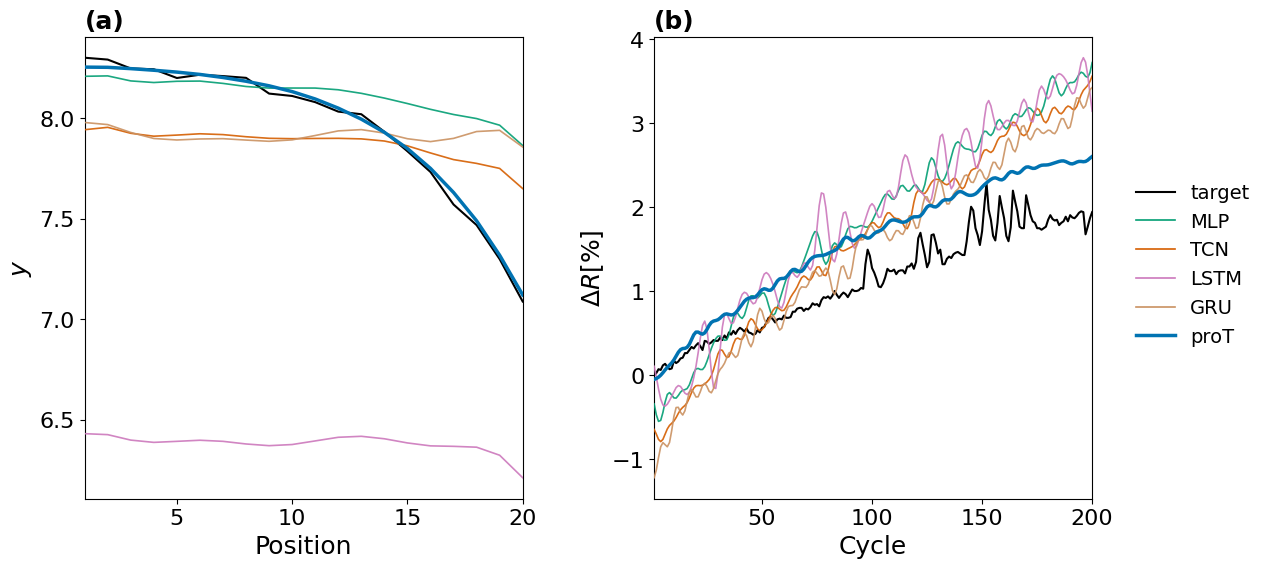

In [10]:
fig = plt.figure(figsize=(13, 6))
gs = gridspec.GridSpec(1, 2, wspace=0.3)

model_order = [m for m in MODELS if m != REF_MODEL] + [REF_MODEL]

for c, (dataset, settings) in enumerate(DATASETS.items()):
    d = data[dataset]
    ax = fig.add_subplot(gs[0, c])
    order = [m for m in model_order if m in d["outputs"]]

    ax, mae = plot_benchmark_panel(
        sample_id=d["sample"],
        var_index=d["feats"]["var"],
        x_index=d["feats"]["pos"],
        val_index=d["feats"]["val"],
        target_array=d["targets"],
        outputs={m: d["outputs"][m] for m in order},
        ref_model=REF_MODEL,
        selected_var=SELECTED_VAR[dataset],
        scale=settings["scale"],
        ax=ax,
        color_map=COLOR_MAP,
        ref_color=COLOR_MAP[REF_MODEL],
        bench_linewidth=BENCH_LW,
        ref_linewidth=REF_LW,
        target_linewidth=TRG_LW,
        xlabel=settings["xlabel"],
        ylabel=settings["ylabel"],
        show_legend=False,
        model_order=order,
    )
    ax.set_title(settings["panel"], loc="left", fontweight="bold")
    print(dataset, f"sample {d['sample']} MAE:", {k: round(v, 4) for k, v in mae.items()})

# --- shared colour legend ---
handles, labels = benchmark_legend_handles(
    model_order=model_order,
    color_map=COLOR_MAP,
    ref_model=REF_MODEL,
    bench_linewidth=BENCH_LW,
    ref_linewidth=REF_LW,
    target_linewidth=TRG_LW,
)
fig.legend(
    handles,
    labels,
    loc="center left",
    bbox_to_anchor=(0.92, 0.5),
    frameon=False,
    ncol=1,
)

for fmt in ["pdf", "svg", "png"]:
    out_path = join(save_dir, f"fig_benchmark_predictions.{fmt}")
    fig.savefig(out_path, format=fmt, bbox_inches="tight", dpi=360)

plt.show()

## Figure: final value (true vs predicted)

For every test sample the value at the largest position of the plotted target variable is
compared with the model prediction at the same step.

In [11]:
last_values = {}
for dataset, d in data.items():
    df_last = last_value_df(
        target_array=d["targets"],
        outputs={m: d["outputs"][m] for m in MODELS if m in d["outputs"]},
        var_index=d["feats"]["var"],
        x_index=d["feats"]["pos"],
        val_index=d["feats"]["val"],
        selected_var=SELECTED_VAR[dataset],
        scale=DATASETS[dataset]["scale"],
    )
    last_values[dataset] = df_last
    print(dataset, "samples:", df_last["index"].nunique(), "rows:", len(df_last))

last_values["ishigami"].head()

ishigami samples: 3200 rows: 16000
dyconex samples: 384 rows: 1920


,index,model,position,true,pred
0,0,MLP,20.0,8.041703,7.954576
1,0,TCN,20.0,8.041703,7.943419
2,0,LSTM,20.0,8.041703,6.429967
3,0,GRU,20.0,8.041703,8.123522
4,0,proT,20.0,8.041703,8.041714


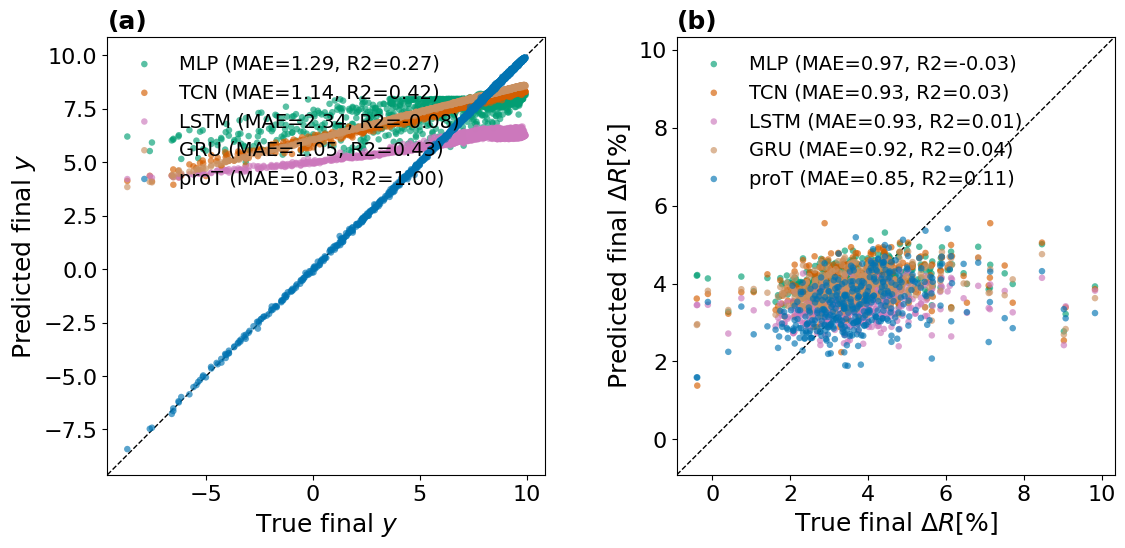

In [12]:
PANELS_LAST = ["(a)", "(b)"]

fig = plt.figure(figsize=(13, 6))
gs = gridspec.GridSpec(1, 2, wspace=0.3)

for c, (dataset, settings) in enumerate(DATASETS.items()):
    ax = fig.add_subplot(gs[0, c])
    plot_last_value_parity(
        last_values[dataset],
        model_order=[m for m in MODELS if m in data[dataset]["outputs"]],
        color_map=COLOR_MAP,
        ax=ax,
        xlabel=f"True final {settings['ylabel']}",
        ylabel=f"Predicted final {settings['ylabel']}",
        show_metrics_in_legend=True,
        legend_position="upper left",
    )
    ax.set_title(PANELS_LAST[c], loc="left", fontweight="bold")

for fmt in ["pdf", "svg", "png"]:
    out_path = join(save_dir, f"fig_benchmark_last_value.{fmt}")
    fig.savefig(out_path, format=fmt, bbox_inches="tight", dpi=360)

plt.show()

## Figure: proT training history and test MAE density (synthetic)

Synthetic dataset (`ishigami`) only, proT with the benchmark-optimized checkpoint
(best optuna trial). Same layout as the case-study figure: (a) validation MAE vs
epoch (mean +/- std across the folds of the best trial), training MAE dashed, star
at the best checkpoint used for prediction; (b) density of the per-sample test MAE.

Best checkpoint: epoch 199, val MAE 0.0022


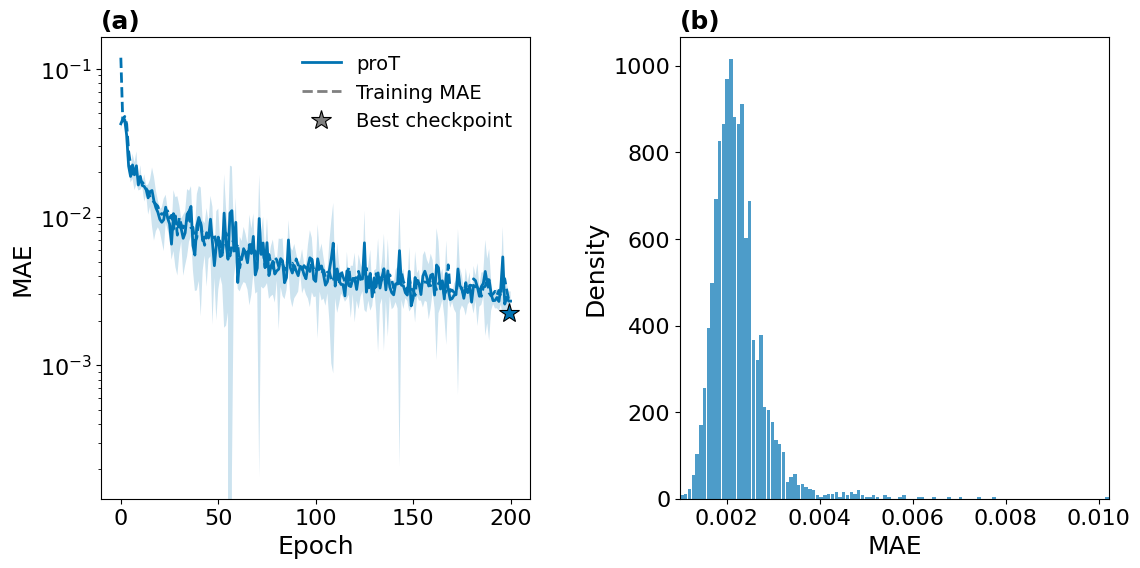

In [13]:
SYN = "ishigami"
exp_path_syn = find_experiment_folder(baseline_dir, REF_MODEL, SYN, FUSION)
d_syn = data[SYN]
df_mae_syn = d_syn["metrics_dfs"][REF_MODEL]
var_syn = SELECTED_VAR[SYN]
settings_syn = DATASETS[SYN]

fig = plt.figure(figsize=(13, 6))
gs = gridspec.GridSpec(1, 2, wspace=0.35)

# --- Left panel: validation MAE vs epoch (mean +/- std across folds) ---
ax1 = fig.add_subplot(gs[0])
hist_val = load_trial_history(exp_path_syn, metric="val_mae")
hist_train = load_trial_history(exp_path_syn, metric="train_mae")
std = hist_val["std"].fillna(0.0)  # epochs covered by a single fold get no band

ax1.plot(hist_val["epoch"], hist_val["mean"], label=REF_MODEL, color=COLOR_MAP[REF_MODEL])
ax1.fill_between(
    hist_val["epoch"],
    hist_val["mean"] - std,
    hist_val["mean"] + std,
    color=COLOR_MAP[REF_MODEL],
    alpha=0.2,
    linewidth=0,
)
# training MAE (mean across folds) as dashed line, same color
ax1.plot(hist_train["epoch"], hist_train["mean"], color=COLOR_MAP[REF_MODEL], linestyle="--")

# star at the best checkpoint used for prediction
best_epoch, best_val_mae = load_best_checkpoint_epoch(exp_path_syn, optuna=True)
ax1.plot(
    best_epoch, best_val_mae,
    marker="*", markersize=15, linestyle="None",
    color=COLOR_MAP[REF_MODEL], markeredgecolor="black", markeredgewidth=0.8,
    zorder=5, clip_on=False,
)
print(f"Best checkpoint: epoch {best_epoch}, val MAE {best_val_mae:.4f}")

# legend proxies for the dashed training curve and the best-checkpoint star
ax1.plot([], [], color="gray", linestyle="--", label="Training MAE")
ax1.plot([], [], marker="*", markersize=15, linestyle="None", color="gray",
         markeredgecolor="black", markeredgewidth=0.8, label="Best checkpoint")

ax1.set_yscale("log")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("MAE")
ax1.legend(frameon=False)
ax1.set_title("(a)", loc="left", fontweight="bold")

# --- Right panel: test MAE density ---
ax2 = fig.add_subplot(gs[1])
sns.histplot(
    data=df_mae_syn,
    x="MAE",
    color=COLOR_MAP[REF_MODEL],
    edgecolor=None,
    alpha=0.7,
    linewidth=0,
    shrink=0.9,
    legend=False,
    stat="density",
    ax=ax2,
)
ax2.set_xlim(min(df_mae_syn["MAE"]), max(df_mae_syn["MAE"]))
ax2.set_title("(b)", loc="left", fontweight="bold")

# --- Save in multiple formats ---
for fmt in ["pdf", "svg", "png"]:
    out_path = join(save_dir, f"fig_benchmark_ishigami_mae_history.{fmt}")
    fig.savefig(out_path, format=fmt, bbox_inches="tight", dpi=360)

plt.show()

## Figure: proT predictions, good vs bad sample (synthetic)

Analog of the case-study good/bad figure on the synthetic dataset: (a) the test
sample with the lowest positive final value, (b) the test sample with the highest
final value. The candidate lists below are only for inspection; the final choice is
set explicitly in `good_idx`/`bad_idx` so the figure is reproducible.

In [14]:
# --- Candidate samples by percentile of the final value ---
print("Low end (positive values only):")
print_percentile_candidates(
    d_syn["targets"], d_syn["feats"]["var"], d_syn["feats"]["val"],
    percentiles=[0, 1, 2, 5, 10], selected_vars=(var_syn,),
    positive_only=True, mae_df=df_mae_syn,
)
print("\nHigh end:")
print_percentile_candidates(
    d_syn["targets"], d_syn["feats"]["var"], d_syn["feats"]["val"],
    percentiles=[90, 95, 98, 99, 100], selected_vars=(var_syn,),
    mae_df=df_mae_syn,
)

# automatic defaults: lowest positive / highest final value
good_idx_auto, good_fval = pick_final_value_sample(
    d_syn["targets"], d_syn["feats"]["var"], d_syn["feats"]["val"],
    selected_vars=(var_syn,), mode="min",
)
bad_idx_auto, bad_fval = pick_final_value_sample(
    d_syn["targets"], d_syn["feats"]["var"], d_syn["feats"]["val"],
    selected_vars=(var_syn,), mode="max",
)
print(f"Automatic: good_idx={good_idx_auto} (final value {good_fval:.4f}), "
      f"bad_idx={bad_idx_auto} (final value {bad_fval:.4f})")

Low end (positive values only):
   pct  index  final_value        MAE
   0.0   1449       0.0005     0.0021
   1.0   2545       0.1135     0.0026
   2.0   2803       0.1866     0.0025
   5.0   2242       0.3869     0.0030
  10.0   3153       0.5920     0.0018

High end:
   pct  index  final_value        MAE
  90.0   2740       0.9631     0.0024
  95.0   2367       0.9742     0.0019
  98.0   2706       0.9820     0.0020
  99.0    123       0.9853     0.0019
 100.0   1617       0.9941     0.0027
Automatic: good_idx=1449 (final value 0.0005), bad_idx=1617 (final value 0.9941)


In [25]:
# --- MANUAL SELECTION: edit these two ids after inspecting the candidate lists ---
good_idx = good_idx_auto
bad_idx = bad_idx_auto

print(f"Selected: good_idx={good_idx}, bad_idx={bad_idx}")

Selected: good_idx=1449, bad_idx=1617


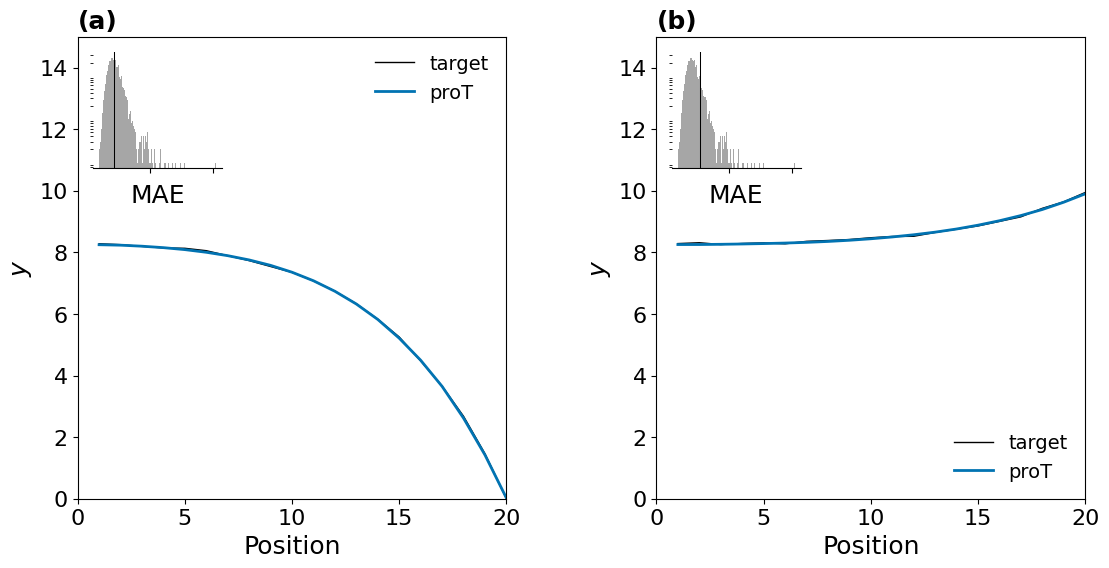

In [26]:
fig = plt.figure(figsize=(13, 6))
gs = gridspec.GridSpec(1, 2, wspace=0.35)

# --- Shared y-axis limits across panels ---
ylim_shared = shared_ylim(
    [good_idx, bad_idx],
    d_syn["targets"],
    d_syn["outputs"][REF_MODEL],
    d_syn["feats"]["var"],
    d_syn["feats"]["val"],
    selected_vars=(var_syn,),
    scale=settings_syn["scale"],
)

ylim_shared = (0,15)

# --- Left panel: good sample (lowest positive final value) ---
ax1 = fig.add_subplot(gs[0])
plot_predictions_enhanced(
    sample_id=good_idx,
    var_index=d_syn["feats"]["var"],
    x_index=d_syn["feats"]["pos"],
    val_index=d_syn["feats"]["val"],
    target_array=d_syn["targets"],
    output_array=[(d_syn["outputs"][REF_MODEL], REF_MODEL)],
    selected_var=var_syn,
    ylim=ylim_shared,
    mae_df=df_mae_syn,
    inset_position="upper left",
    legend_position="upper right",
    show_metrics_in_legend=False,
    ax=ax1,
    show_inset=True,
    scale=settings_syn["scale"],
    xlabel=settings_syn["xlabel"],
    ylabel=settings_syn["ylabel"],
    color_map={REF_MODEL: COLOR_MAP[REF_MODEL]},
)
ax1.set_title("(a)", loc="left", fontweight="bold")

# --- Right panel: bad sample (highest final value) ---
ax2 = fig.add_subplot(gs[1])
plot_predictions_enhanced(
    sample_id=bad_idx,
    var_index=d_syn["feats"]["var"],
    x_index=d_syn["feats"]["pos"],
    val_index=d_syn["feats"]["val"],
    target_array=d_syn["targets"],
    output_array=[(d_syn["outputs"][REF_MODEL], REF_MODEL)],
    selected_var=var_syn,
    ylim=ylim_shared,
    mae_df=df_mae_syn,
    inset_position="upper left",
    legend_position="lower right",
    show_metrics_in_legend=False,
    ax=ax2,
    show_inset=True,
    scale=settings_syn["scale"],
    xlabel=settings_syn["xlabel"],
    ylabel=settings_syn["ylabel"],
    color_map={REF_MODEL: COLOR_MAP[REF_MODEL]},
)
ax2.set_title("(b)", loc="left", fontweight="bold")

# --- Save in multiple formats ---
for fmt in ["pdf", "svg", "png"]:
    out_path = join(save_dir, f"fig_benchmark_ishigami_good_bad.{fmt}")
    fig.savefig(out_path, format=fmt, bbox_inches="tight", dpi=360)

plt.show()